In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, welch
from google.colab import files
from scipy.io import loadmat

In [ ]:
uploaded = files.upload()
filename = list(uploaded.keys())[0]
data = loadmat(filename)

Saving Backward Lean.mat to Backward Lean.mat


In [ ]:
for name in data:
    if not name.startswith("__"):
        print(name)

SamplingFrequency
Data
Time
Description
OTBFile


In [ ]:
emg = data["Data"]
time = data["Time"]
fs = data["SamplingFrequency"]

print("EMG shape:", emg.shape)
print("Time shape:", time.shape)
print("Sampling Frequency shape:", fs.shape, "Sampling Frequency value:", fs[0,0])

EMG shape: (61750, 2)
Time shape: (61750, 1)
Sampling Frequency shape: (1, 1) Sampling Frequency value: 2000.0


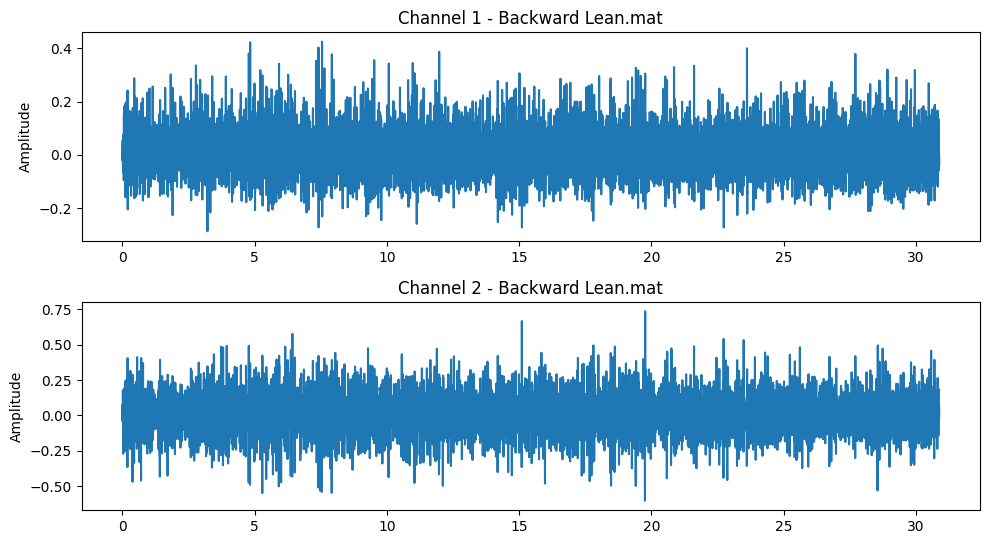

In [ ]:
plt.figure(figsize=(10,8))

plt.subplot(3,1,1)
plt.plot(time, emg[:,0])
plt.title("Channel 1 - " + filename)
plt.ylabel("Amplitude")

plt.subplot(3,1,2)
plt.plot(time, emg[:,1])
plt.title("Channel 2 - " + filename)
plt.ylabel("Amplitude")


plt.tight_layout()
plt.show()

/tmp/ipykernel_2280/4077662960.py:3: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  window = int(window_seconds * fs / 2)


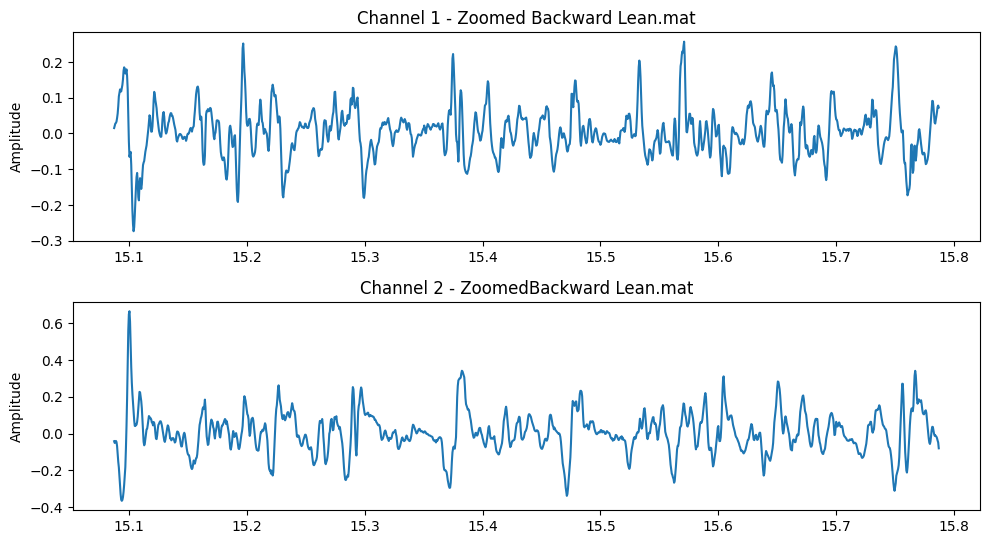

In [ ]:
middle = len(time) // 2
window_seconds = 0.7
window = int(window_seconds * fs / 2)

start = middle - window
end = middle + window

plt.figure(figsize=(10,8))

plt.subplot(3,1,1)
plt.plot(time[start:end], emg[start:end,0])
plt.title("Channel 1 - Zoomed " + filename)
plt.ylabel("Amplitude")

plt.subplot(3,1,2)
plt.plot(time[start:end], emg[start:end,1])
plt.title("Channel 2 - Zoomed" + filename)
plt.ylabel("Amplitude")


plt.tight_layout()
plt.show()

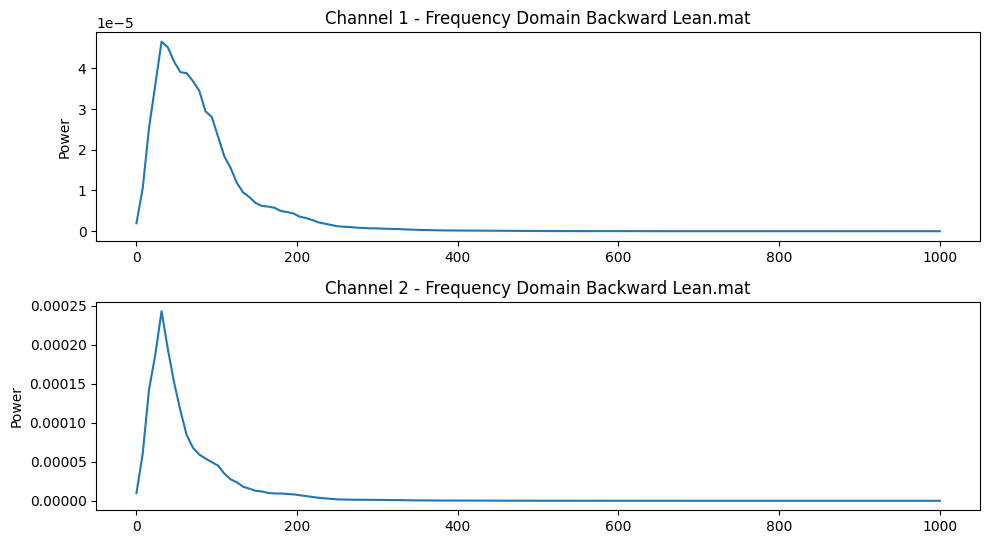

In [ ]:
fs_scalar = fs[0,0]

f1, pxx1 = welch(emg[:,0], fs_scalar)
f30, pxx30 = welch(emg[:,1], fs_scalar)


plt.figure(figsize=(10,8))

plt.subplot(3,1,1)
plt.plot(f1, pxx1)
plt.title("Channel 1 - Frequency Domain "  + filename)
plt.ylabel("Power")

plt.subplot(3,1,2)
plt.plot(f30, pxx30)
plt.title("Channel 2 - Frequency Domain "+ filename)
plt.ylabel("Power")


plt.tight_layout()
plt.show()

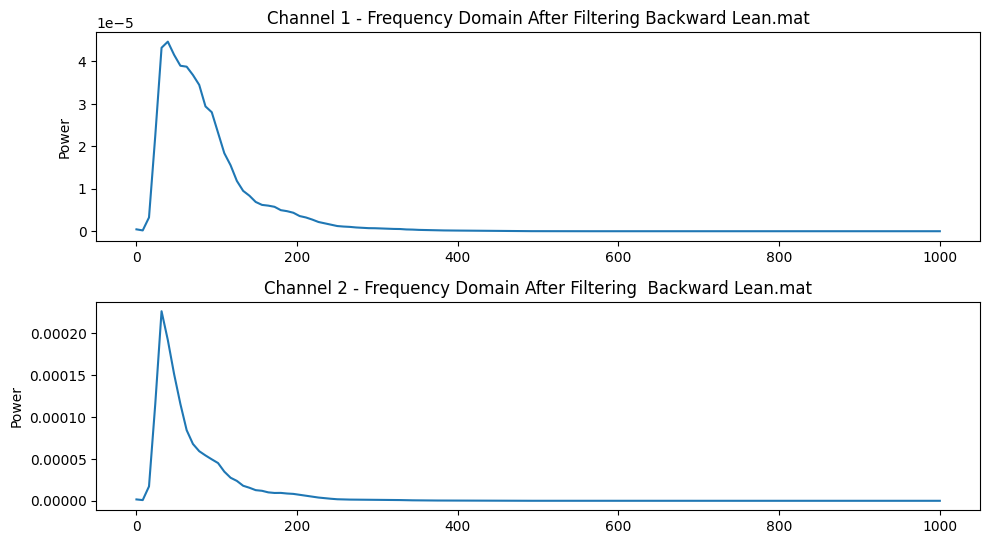

In [ ]:
low = 20
high = 500

b, a = butter(4, [low/(fs[0,0]/2), high/(fs[0,0]/2)], btype="bandpass")

emg_filtered = filtfilt(b, a, emg, axis=0)

f1, pxx1 = welch(emg_filtered[:,0], fs[0,0])
# f30, pxx30 = welch(emg_filtered[:,29], fs[0,0])
# f60, pxx60 = welch(emg_filtered[:,59], fs[0,0])

f30, pxx30 = welch(emg_filtered[:,1], fs[0,0])

plt.figure(figsize=(10,8))

plt.subplot(3,1,1)
plt.plot(f1, pxx1)
plt.title("Channel 1 - Frequency Domain After Filtering " + filename)
plt.ylabel("Power")

plt.subplot(3,1,2)
plt.plot(f30, pxx30)
plt.title("Channel 2 - Frequency Domain After Filtering  " + filename)
plt.ylabel("Power")


plt.tight_layout()
plt.show()

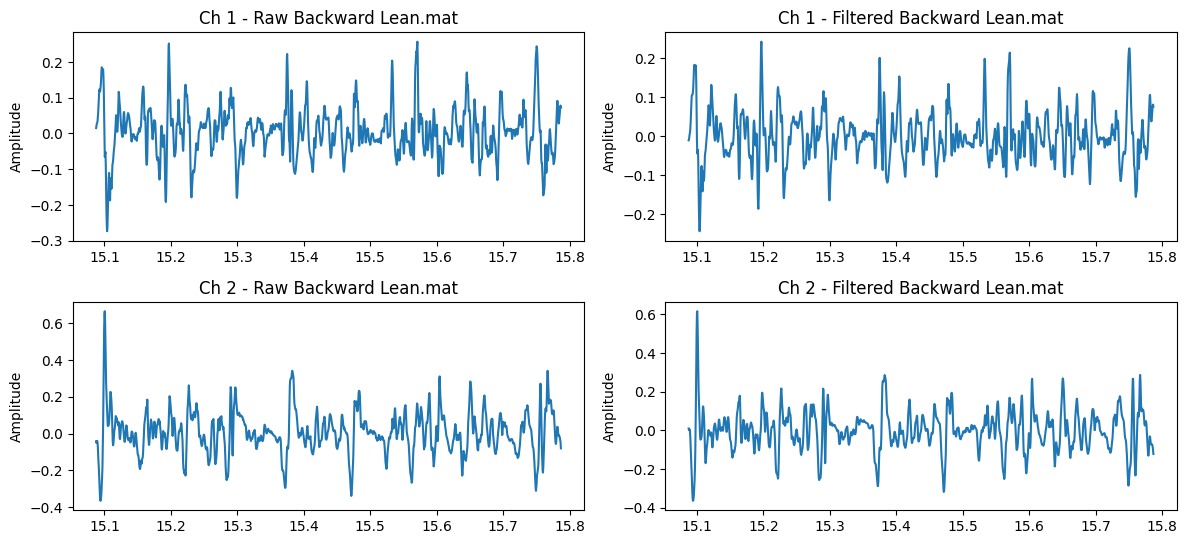

In [ ]:
plt.figure(figsize=(12,8))

plt.subplot(3,2,1)
plt.plot(time[start:end], emg[start:end,0])
plt.title("Ch 1 - Raw "+ filename)
plt.ylabel("Amplitude")

plt.subplot(3,2,2)
plt.plot(time[start:end], emg_filtered[start:end,0])
plt.title("Ch 1 - Filtered " + filename)
plt.ylabel("Amplitude")

plt.subplot(3,2,3)
plt.plot(time[start:end], emg[start:end,1])
plt.title("Ch 2 - Raw "+ filename)
plt.ylabel("Amplitude")

plt.subplot(3,2,4)
plt.plot(time[start:end], emg_filtered[start:end,1])
plt.title("Ch 2 - Filtered " + filename)
plt.ylabel("Amplitude")


plt.tight_layout()
plt.show()

In [ ]:
rms_ch1 = np.sqrt(np.mean(emg_filtered[:,0]**2))
rms_ch2 = np.sqrt(np.mean(emg_filtered[:,1]**2))


print("RMS of Channel 1:",rms_ch1)
print("RMS of Channel 2:",rms_ch2)

RMS of Channel 1: 0.06320533233273118
RMS of Channel 2: 0.10462969182596217


In [ ]:
rms_table = pd.DataFrame({
    "RMS_TargetMuscle1": [rms_ch1],
    "RMS_TargetMuscle2": [rms_ch2]
})

rms_table.to_excel("RMS_Channels.xlsx", index=False)

In [ ]:
def median_frequency(signal, fs):
    signal = np.asarray(signal).squeeze()
    fs = float(np.asarray(fs).squeeze())

    f, pxx = welch(signal, fs=fs)

    f = np.asarray(f).squeeze()
    pxx = np.asarray(pxx).squeeze()

    cumulative_power = np.cumsum(pxx)
    half_power = cumulative_power[-1] / 2

    median_index = np.searchsorted(cumulative_power, half_power)
    median_freq = float(f[median_index])

    return median_freq

mf_ch1 = median_frequency(emg_filtered[:, 0], fs)
mf_ch2 = median_frequency(emg_filtered[:, 1], fs)

mf_table = pd.DataFrame({
    "Channel": [1, 2],
    "Median_Frequency_Hz": [mf_ch1, mf_ch2]
})

print(mf_table)
mf_table.to_excel("Median_Frequency_Channels.xlsx", index=False)

   Channel  Median_Frequency_Hz
0        1              70.3125
1        2              54.6875


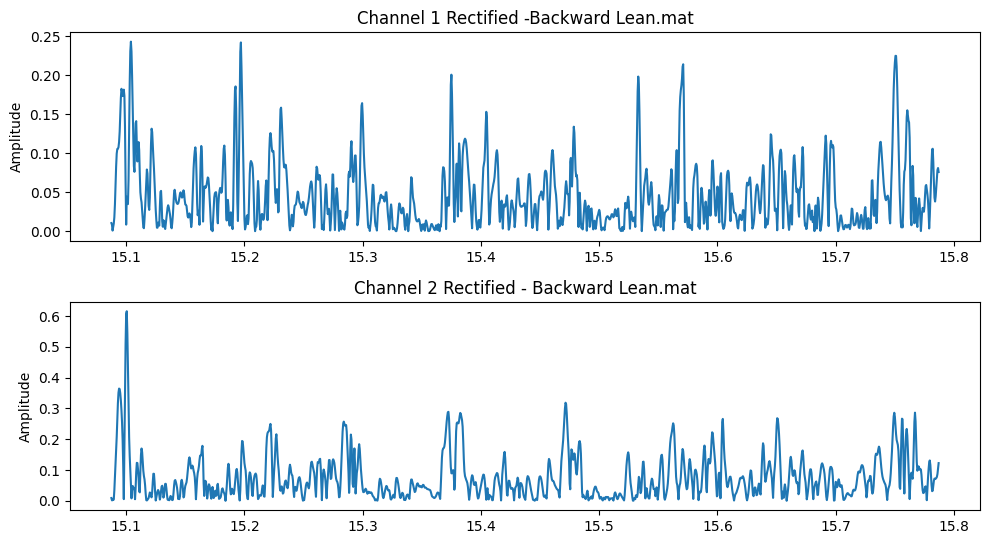

In [ ]:
emg_rectified = np.abs(emg_filtered)

plt.figure(figsize=(10,8))

plt.subplot(3,1,1)
plt.plot(time[start:end], emg_rectified[start:end,0])
plt.title("Channel 1 Rectified -" + filename)
plt.ylabel("Amplitude")

plt.subplot(3,1,2)
plt.plot(time[start:end], emg_rectified[start:end,1])
plt.title("Channel 2 Rectified - " + filename)
plt.ylabel("Amplitude")


plt.tight_layout()
plt.show()

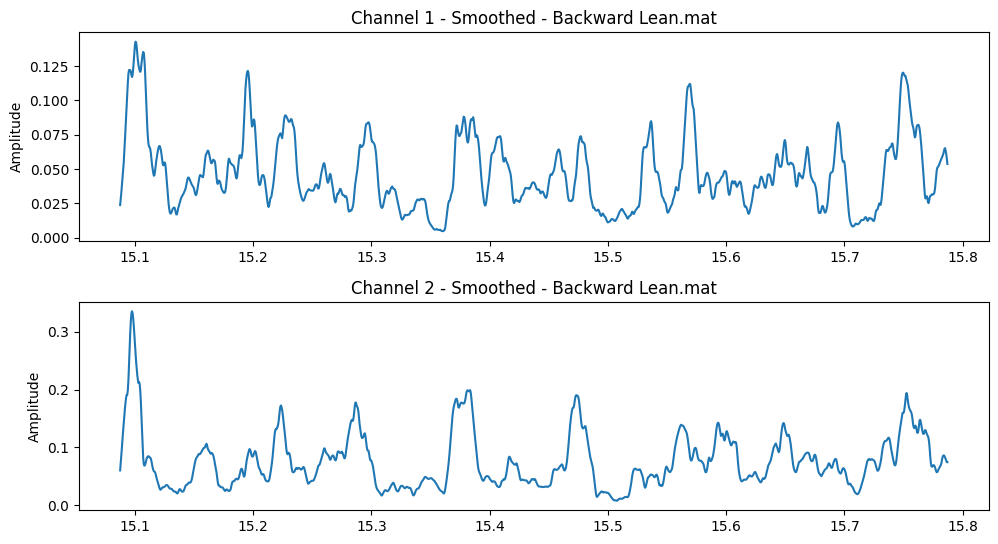

In [ ]:
window = 20

emg_smoothed = np.zeros_like(emg_rectified)

for ch in range(emg_rectified.shape[1]):
    emg_smoothed[:,ch] = np.convolve(emg_rectified[:,ch], np.ones(window)/window, mode="same")

plt.figure(figsize=(10,8))

plt.subplot(3,1,1)
plt.plot(time[start:end], emg_smoothed[start:end,0])
plt.title("Channel 1 - Smoothed - " + filename)
plt.ylabel("Amplitude")

plt.subplot(3,1,2)
plt.plot(time[start:end], emg_smoothed[start:end,1])
plt.title("Channel 2 - Smoothed - " + filename)
plt.ylabel("Amplitude")


plt.tight_layout()
plt.show()